In [2]:
import numpy as np
import pandas as pd

### 1

In [21]:
table_data_1 = {
    "Высота волны (м)": [6,1,7,7,2,10],
    "Период воды (сек)": [15,6,10,12,2,2],
    "Скорость ветра (м/с)": [5,9,4,3,10,20],
    "Решение": list(map(bool, [1,0,1,1,0,0]))
}
df1 = pd.DataFrame(table_data_1)
df1.loc[len(df1)] = [8,2,18, None]
df1

,Высота волны (м),Период воды (сек),Скорость ветра (м/с),Решение
0,6.0,15.0,5.0,True
1,1.0,6.0,9.0,False
2,7.0,10.0,4.0,True
3,7.0,12.0,3.0,True
4,2.0,2.0,10.0,False
5,10.0,2.0,20.0,False
6,8.0,2.0,18.0,NaN


In [73]:
features = df1.columns[:-1]
target = df1.iloc[-1][features]
df1["Расстояние"] = (((df1[features] - target)**2)).sum(axis=1)**0.5
df1

,Высота волны (м),Период воды (сек),Скорость ветра (м/с),Решение,Расстояние
0,6.0,15.0,5.0,True,18.493242
1,1.0,6.0,9.0,False,12.083046
2,7.0,10.0,4.0,True,16.155494
3,7.0,12.0,3.0,True,18.05547
4,2.0,2.0,10.0,False,10.0
5,10.0,2.0,20.0,False,2.828427
6,8.0,2.0,18.0,NaN,0.0


In [105]:
top = df1.sort_values("Расстояние").iloc[1:5]
print("Решение:", top['Решение'].value_counts().idxmax())

Решение: False


### 2

In [94]:
table_data_2 = {
    "Money": [3,1,0,0,0],
    "Free":	[0,2,0,0,1],
    "For":	[0,1,1,1,0],
    "Gambling":	[0,1,1,0,0],
    "Fun":	[0,1,1,3,0],
    "Machine":	[0,0,0,1,1],
    "Learning":[0,0,0,1,1],
    "Спам": list(map(bool, [1,1,1,0,0]))
}
df2 = pd.DataFrame(table_data_2)
df2.loc[len(df2)] = [0,1,1,0,0,1,1, None]
df2

,Money,Free,For,Gambling,Fun,Machine,Learning,Спам
0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,True
1,1.0,2.0,1.0,1.0,1.0,0.0,0.0,True
2,0.0,0.0,1.0,1.0,1.0,0.0,0.0,True
3,0.0,0.0,1.0,0.0,3.0,1.0,1.0,False
4,0.0,1.0,0.0,0.0,0.0,1.0,1.0,False
5,0.0,1.0,1.0,0.0,0.0,1.0,1.0,NaN


In [98]:
features = df2.columns[:-1]
target = df2.iloc[-1][features]
df2["Расстояние"] = abs(df2[features] - target).sum(axis=1)
df2

,Money,Free,For,Gambling,Fun,Machine,Learning,Спам,Расстояние
0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,True,7.0
1,1.0,2.0,1.0,1.0,1.0,0.0,0.0,True,6.0
2,0.0,0.0,1.0,1.0,1.0,0.0,0.0,True,5.0
3,0.0,0.0,1.0,0.0,3.0,1.0,1.0,False,4.0
4,0.0,1.0,0.0,0.0,0.0,1.0,1.0,False,1.0
5,0.0,1.0,1.0,0.0,0.0,1.0,1.0,NaN,0.0


In [103]:
top = df2.sort_values("Расстояние").iloc[1:4]
print("Спам:", top.value_counts("Спам").idxmax())

Спам: False


### 3

In [140]:
w0 = -3.82398
age = -0.02990
group = {0: 0, 1: -0.09089, 2: -0.19558}
cost = 0.02999
coutn = 0.74572

table_data_3 = {
    "age": [56, 21, 32,48, 37],
    "group": [1,2,0, 1, 2],
    "cost": [1.6, 4.92, 1.08, 1.21, 0.72],
    "coutn": [109.32, 11.28, 165.39, 161.19, 170.65]
}
df3 = pd.DataFrame(table_data_3)

df3

,age,group,cost,coutn
0,56,1,1.60,109.32
1,21,2,4.92,11.28
2,32,0,1.08,165.39
3,48,1,1.21,161.19
4,37,2,0.72,170.65


In [141]:
df3['Регрессия шаг 1'] = w0 + df3["age"] * age + df3['group'] + df3['cost'] * cost + df3['coutn'] * coutn + df3['group'].map(group)
df3['Регрессия шаг 2'] = 1 / (1 + np.exp(-df3["Регрессия шаг 1"]))
df3["Решение"] = df3["Регрессия шаг 2"] > 0.75 
df3

,age,group,cost,coutn,Регрессия шаг 1,Регрессия шаг 2,Решение
0,56,1,1.60,109.32,76.980824,1.0000,True
1,21,2,4.92,11.28,5.911812,0.9973,True
2,32,0,1.08,165.39,118.586240,1.0000,True
3,48,1,1.21,161.19,115.888825,1.0000,True
4,37,2,0.72,170.65,124.152851,1.0000,True


### 4
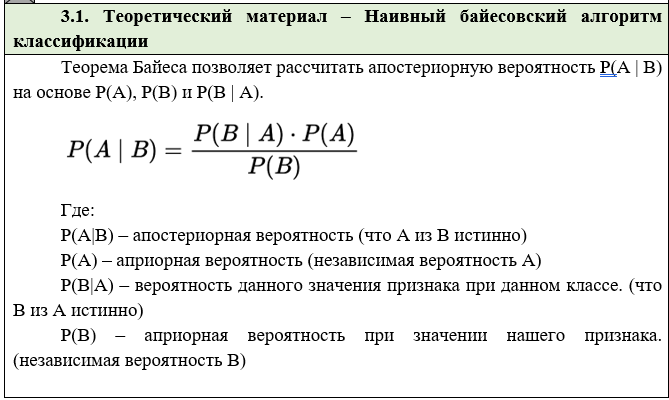
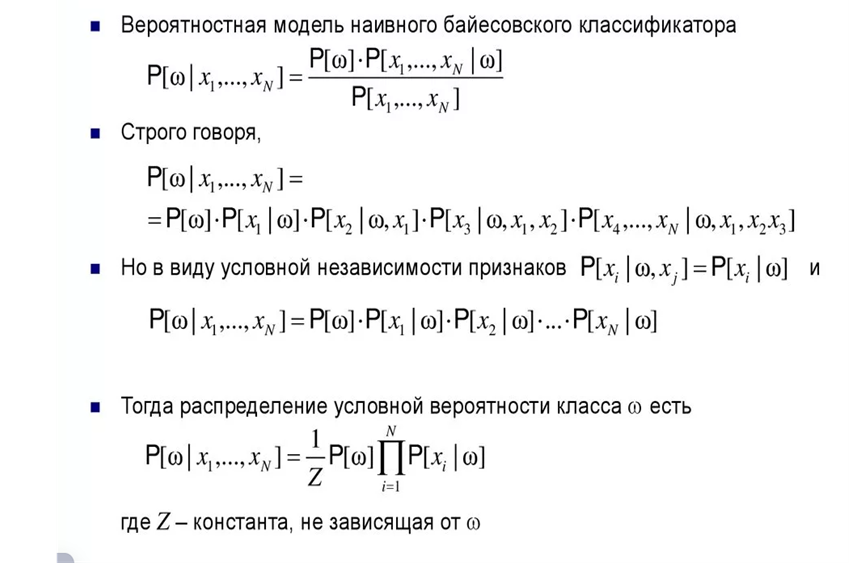

In [ ]:
import pandas as pd
from scipy.stats import norm

# 1. Данные
data = {
    'a1': ['T', 'T', 'T', 'F', 'F', 'F', 'F', 'T', 'F'],
    'a2': ['T', 'T', 'F', 'F', 'T', 'T', 'F', 'F', 'T'],
    'a3': [5.0, 7.0, 8.0, 3.0, 7.0, 4.0, 5.0, 6.0, 1.0],
    'class': ['Y', 'Y', 'N', 'Y', 'N', 'N', 'N', 'Y', 'N']
}
df = pd.DataFrame(data)

test_a1, test_a2, test_a3 = 'T', 'F', 1.0

classes = ['Y', 'N']
results = {}

for c in classes:
    subset = df[df['class'] == c]
    
    # Априорная вероятность
    prior = len(subset) / len(df)
    
    # Условные вероятности для категориальных признаков
    p_a1 = len(subset[subset['a1'] == test_a1]) / len(subset)
    p_a2 = len(subset[subset['a2'] == test_a2]) / len(subset)
    
    # Плотность вероятности для числового признака a3 (нормальное распределение)
    mu, std = subset['a3'].mean(), subset['a3'].std()
    p_a3 = norm.pdf(test_a3, loc=mu, scale=std)
    
    # Итоговая вероятность без нормализации
    score = prior * p_a1 * p_a2 * p_a3
    results[c] = score
    print(f"Класс {c}: Априорная={prior:.3f}, P(a1|C)={p_a1:.3f}, P(a2|C)={p_a2:.3f}, Плотность a3={p_a3:.4f}, Итог={score:.5f}")

print(f"\nПредсказанный класс: {max(results, key=results.get)}")

Класс Y: Априорная=0.444, P(a1|C)=0.750, P(a2|C)=0.500, Плотность a3=0.0106, Итог=0.00176
Класс N: Априорная=0.556, P(a1|C)=0.200, P(a2|C)=0.400, Плотность a3=0.0501, Итог=0.00223

Предсказанный класс: N
